# MNIST with an empirical score: sampling without a neural network

**Draft worked experiment.** Keep a bank of 1,000 MNIST training images and compute exact softmax responsibilities under isotropic VP corruption. Generate 32 trajectories in the original 784-dimensional pixel space using no trained network, decoder, embedding, labels in the score, or image clipping during integration.

[Part 07 · Empirical-score sampling](../../../tutorials/41-empirical-score-interpolation.html). This small CPU experiment tests interpolation and proximity to stored images; it is not a competitive image generator or a test of population generalization. It uses the same equations as the one-dimensional notebook. Run all cells in order. Requirements: NumPy, SciPy, Matplotlib, threadpoolctl, Jupyter. The first run downloads MNIST from the [CVDF mirror](https://github.com/cvdfoundation/mnist).

## 1. Exact empirical Bayes denoising in pixel space

For image vectors $x_i\in[0,1]^{784}$,
$$w_i(x,t)=\operatorname{softmax}_i\left(\frac{\alpha_t x^Tx_i-\alpha_t^2\|x_i\|^2/2}{\sigma_t^2}\right),\qquad
m_t(x)=\sum_i w_i(x,t)x_i.$$
The common $-\|x\|^2/(2\sigma_t^2)$ term cancels. The score and velocity are
$$s_t(x)=\frac{\alpha_tm_t(x)-x}{\sigma_t^2},\quad v(x,t)=\frac{\beta(t)\alpha_t}{2\sigma_t^2}(\alpha_tx-m_t(x)).$$
For comparison with stored images, posterior means are on the clean pixel scale, whereas raw states at positive time retain contraction and noise. We report both separately.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=2)
np.set_printoptions(precision=5, suppress=True)

def schedule(t):
    beta = 0.1 + 19.9*t
    a = np.exp(-0.05*t - 4.975*t*t)
    s2 = -np.expm1(-0.1*t - 9.95*t*t)
    return a, s2, beta

def posterior(x, t, data, topk=None):
    # x: (batch, dimension), data: (observations, dimension).
    a, s2, _ = schedule(t)
    # Drop the common -||x||^2/(2*s2) term for numerical stability.
    logits = (a*(x @ data.T) - 0.5*a*a*np.sum(data*data, axis=1))/s2
    if topk is not None and topk < len(data):
        ix = np.argpartition(logits, -topk, axis=1)[:, -topk:]
        mask = np.full_like(logits, -np.inf)
        np.put_along_axis(mask, ix, np.take_along_axis(logits, ix, axis=1), axis=1)
        logits = mask
    w = softmax(logits, axis=1)
    return w @ data, w

def velocity(x, t, data, topk=None):
    a, s2, beta = schedule(t)
    m, _ = posterior(x, t, data, topk)
    return beta*a/(2*s2)*(a*x-m)

def integrate(x1, data, steps=600, stops=(0.8,0.6,0.4,0.2,0.1,0.03,0.01), topk=None):
    # Nonuniform times resolve small-noise behavior. No clipping of particles.
    times = np.unique(np.r_[np.geomspace(min(stops), 1., steps+1), stops])[::-1]
    x = np.array(x1, dtype=np.float64, copy=True)
    saved = {1.: x.copy()}
    stopset = set(stops)
    for t, u in zip(times[:-1], times[1:]):
        x += (u-t)*velocity(x, t, data, topk)
        if u in stopset:
            saved[float(u)] = x.copy()
    return saved

def nearest(x, data):
    d2 = np.maximum(np.sum(x*x,1)[:,None] + np.sum(data*data,1)[None,:] - 2*x@data.T, 0)
    ix = np.argmin(d2, axis=1)
    return ix, np.sqrt(d2[np.arange(len(x)),ix]/data.shape[1])

def diagnostics(x, t, data):
    m, w = posterior(x,t,data)
    _, raw_rmse = nearest(x,data)
    _, mean_rmse = nearest(m,data)
    return [raw_rmse.mean(), mean_rmse.mean(), np.mean(1/np.sum(w*w,axis=1)), np.mean(w.max(1))]


## 2. Download and select the data bank

Read the original IDX files. Fix the random subset and preserve its labels only for descriptive diagnostics. The empirical prior has equal mass on the selected 1,000 images, not on all MNIST images. Set `MNIST_CACHE` to reuse an existing directory.

Bank shape: (1000, 784) label counts: [ 95 100 110  93  83  98 106 115 107  93]


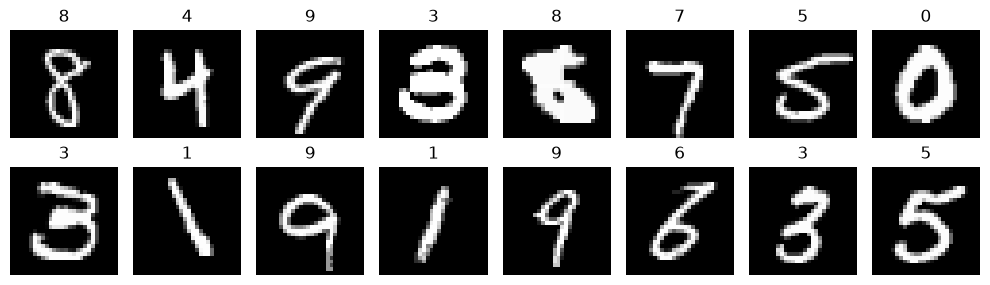

In [2]:
from pathlib import Path
import os, gzip, urllib.request, hashlib, time
cache=Path(os.environ.get('MNIST_CACHE',str(Path.home()/'.cache'/'empirical-score-mnist')))
cache.mkdir(parents=True,exist_ok=True)
files={'train-images-idx3-ubyte.gz':'f68b3c2dcbeaaa9fbdd348bbdeb94873',
       'train-labels-idx1-ubyte.gz':'d53e105ee54ea40749a09fcbcd1e9432'}
for name,digest in files.items():
    path=cache/name
    if not path.exists():
        urllib.request.urlretrieve('https://storage.googleapis.com/cvdf-datasets/mnist/'+name,path)
    assert hashlib.md5(path.read_bytes()).hexdigest()==digest, 'MNIST checksum mismatch'
with gzip.open(cache/'train-images-idx3-ubyte.gz','rb') as f:
    raw=f.read()
images=np.frombuffer(raw,dtype=np.uint8,offset=16).reshape(-1,784)
with gzip.open(cache/'train-labels-idx1-ubyte.gz','rb') as f:
    labels=np.frombuffer(f.read(),dtype=np.uint8,offset=8)
rng=np.random.default_rng(20261014)
indices=rng.choice(len(images),1000,replace=False)
data=images[indices].astype(np.float64)/255
bank_labels=labels[indices]
print('Bank shape:',data.shape,'label counts:',np.bincount(bank_labels,minlength=10))
fig,ax=plt.subplots(2,8,figsize=(10,3))
for a,im,lab in zip(ax.ravel(),data[:16],bank_labels[:16]):
    a.imshow(im.reshape(28,28),cmap='gray',vmin=0,vmax=1); a.set_title(str(lab)); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Two terminal initialization laws

A fresh standard Gaussian has no assigned training origin. For a matched-law control, independently choose a bank index and construct $\alpha_1x_i+\sigma_1z$. We share $z$ to make a paired comparison. This forward corruption is stochastic, not a record of an ODE trajectory. In 784 dimensions, a small scalar $\alpha_1$ alone does not certify that the terminal mixture is close to standard Gaussian.

Use a geometrically refined decreasing grid and record multiple cutoffs. The true low-noise empirical endpoint is singular; never evaluate the score at $t=0$.

In [3]:
BATCH=32
z=rng.normal(size=(BATCH,784))
a1,s21,_=schedule(1.)
matched=a1*data[rng.integers(len(data),size=BATCH)]+np.sqrt(s21)*z
stops=(.8,.6,.4,.2,.1,.03,.01)
start=time.perf_counter()
normal_paths=integrate(z,data,600,stops)
matched_paths=integrate(matched,data,600,stops)
print('Two 32-particle runs, elapsed seconds:',round(time.perf_counter()-start,2))
print('time | raw nearest pixel RMSE | denoised nearest RMSE | effective count | max weight')
for t in stops:
    print(t,np.array(diagnostics(normal_paths[t],t,data)))
for name,paths in [('Gaussian',normal_paths),('matched',matched_paths)]:
    means,w=posterior(paths[.01],.01,data)
    ix,dist=nearest(means,data)
    print(name,'near-bank fraction (RMSE < 1e-4):',np.mean(dist<1e-4),
          'unique nearest bank images:',len(np.unique(ix)),
          'nearest labels:',np.bincount(bank_labels[ix],minlength=10))
# Labels of nearest images do not certify visual quality or population coverage.

Two 32-particle runs, elapsed seconds: 0.72
time | raw nearest pixel RMSE | denoised nearest RMSE | effective count | max weight
0.8 [  0.9955    0.19801 912.26275   0.00256]
0.6 [  0.98309   0.19321 268.37663   0.02786]
0.4 [0.89926 0.0978  7.88491 0.48851]
0.2 [0.58494 0.00084 1.03119 0.98694]
0.1 [0.32117 0.      1.00003 0.99999]
0.03 [0.10861 0.      1.      1.     ]
0.01 [0.04448 0.      1.      1.     ]
Gaussian near-bank fraction (RMSE < 1e-4): 1.0 unique nearest bank images: 32 nearest labels: [2 4 4 3 3 1 3 2 8 2]
matched near-bank fraction (RMSE < 1e-4): 1.0 unique nearest bank images: 32 nearest labels: [2 4 4 3 3 1 3 2 8 2]


## 4. Which bank images supply one trajectory?

For the first Gaussian-initialized particle, show the six stored images with the largest posterior probabilities at each time. An image label gives its **bank index** and weight. It does not use the digit label to compute the weights. This makes the support behind an early blended denoiser visible and lets us check whether its low-noise estimate still blends images.

The second figure measures concentration across all 32 particles. $N_{\rm eff}=1/\sum_iw_i^2$ equals 1 for a single supporting image and 1,000 for uniform weights over the bank. The maximum weight provides another check. At $t=1$, the VP schedule has $\alpha_1>0$, so the initial weights are close to uniform only if the observed values make the likelihoods similar.

t | effective count for first particle | top bank index | top weight
1.000 |    998.36 |   224 | 0.001138
0.800 |    942.10 |   224 | 0.002144
0.600 |    375.01 |   224 | 0.017468
0.400 |      2.05 |   224 | 0.692553
0.200 |      1.00 |   224 | 1.000000
0.100 |      1.00 |   224 | 1.000000
0.030 |      1.00 |   224 | 1.000000
0.010 |      1.00 |   224 | 1.000000


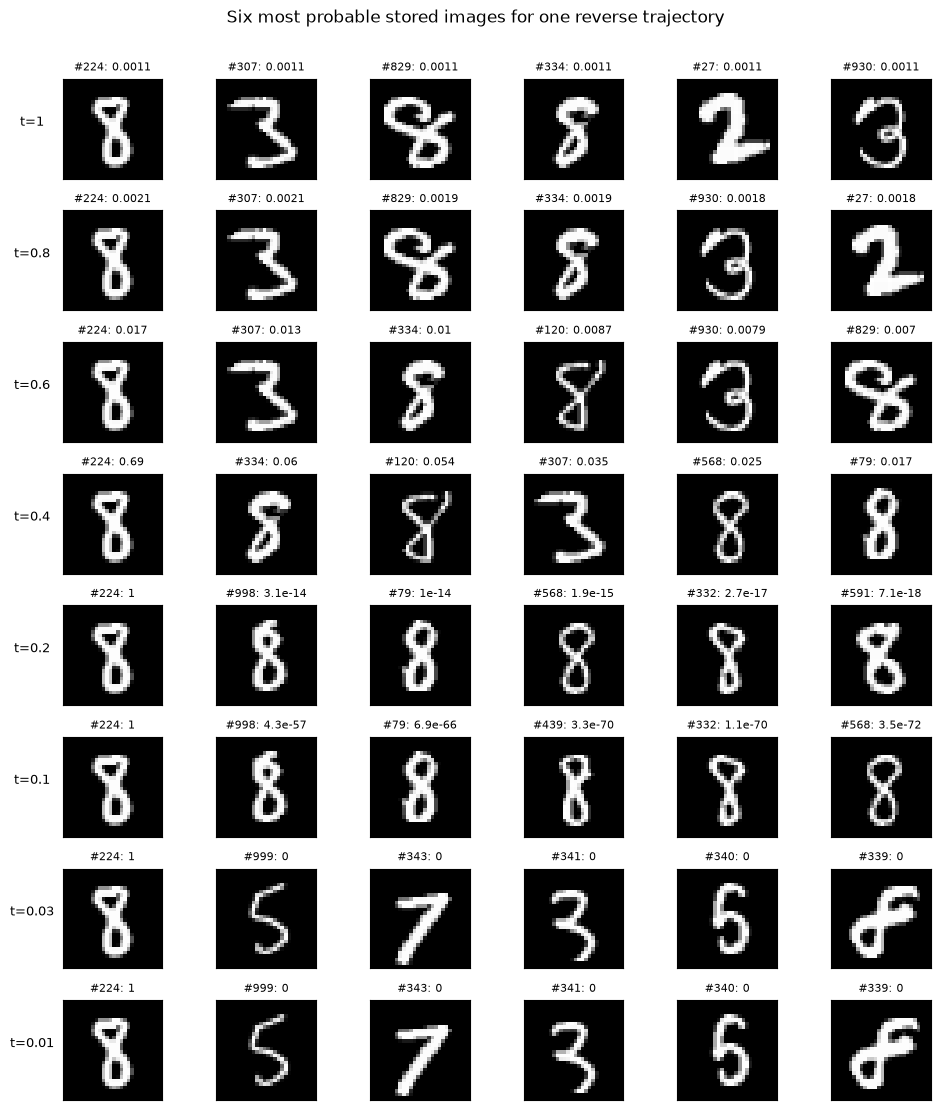

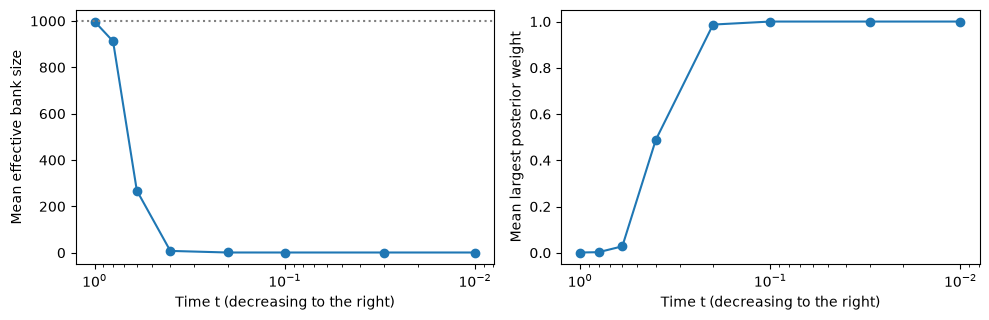

In [4]:
weight_times=[1.,.8,.6,.4,.2,.1,.03,.01]
fig,axes=plt.subplots(len(weight_times),6,figsize=(10,11))
print('t | effective count for first particle | top bank index | top weight')
for row,t in enumerate(weight_times):
    _,w=posterior(normal_paths[t][:1],t,data)
    w=w[0]
    top=np.argsort(w)[-6:][::-1]
    for col,i in enumerate(top):
        axes[row,col].imshow(data[i].reshape(28,28),cmap='gray',vmin=0,vmax=1)
        axes[row,col].set_title(f'#{i}: {w[i]:.2g}',fontsize=8)
        axes[row,col].set_xticks([]);axes[row,col].set_yticks([])
    axes[row,0].set_ylabel(f't={t:g}',rotation=0,labelpad=22,fontsize=9)
    print(f'{t:5.3f} | {1/np.sum(w*w):9.2f} | {top[0]:5d} | {w[top[0]]:.6f}')
fig.suptitle('Six most probable stored images for one reverse trajectory',y=1.005)
plt.tight_layout();plt.show()
mean_neff=[];mean_max=[]
for t in weight_times:
    _,w=posterior(normal_paths[t],t,data)
    mean_neff.append(np.mean(1/np.sum(w*w,axis=1)))
    mean_max.append(np.mean(w.max(axis=1)))
fig,ax=plt.subplots(1,2,figsize=(10,3.3))
ax[0].plot(weight_times,mean_neff,'o-');ax[0].axhline(len(data),color='gray',ls=':')
ax[0].set_ylabel('Mean effective bank size')
ax[1].plot(weight_times,mean_max,'o-');ax[1].set_ylabel('Mean largest posterior weight')
for a in ax:
    a.set_xscale('log');a.invert_xaxis();a.set_xlabel('Time t (decreasing to the right)')
plt.tight_layout();plt.show()

## 5. Follow denoised estimates and compare with stored images

Rows show posterior means along the same eight trajectories. High-noise estimates can average many digits; low-noise estimates may select a single stored digit. The final row is the nearest stored image to the final denoised output. The images shown are the first eight particles, without selection for appearance. Raw states are separately displayed with a fixed grayscale range; only the display saturates values outside [0,1].

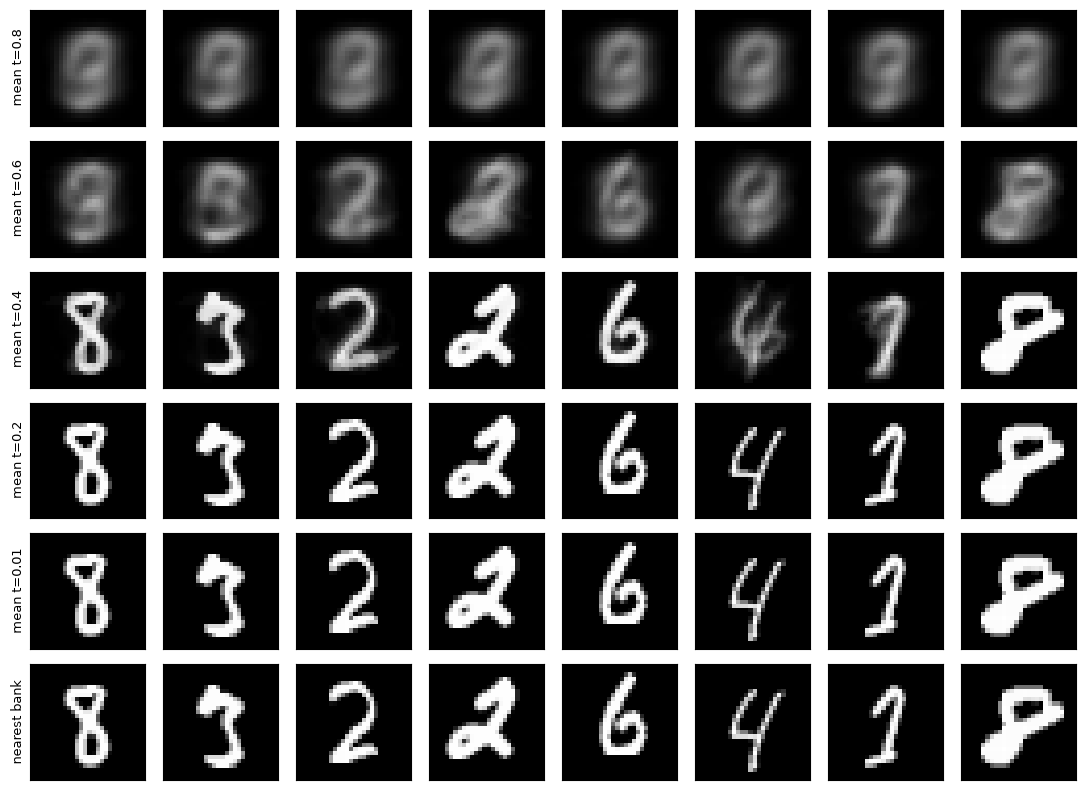

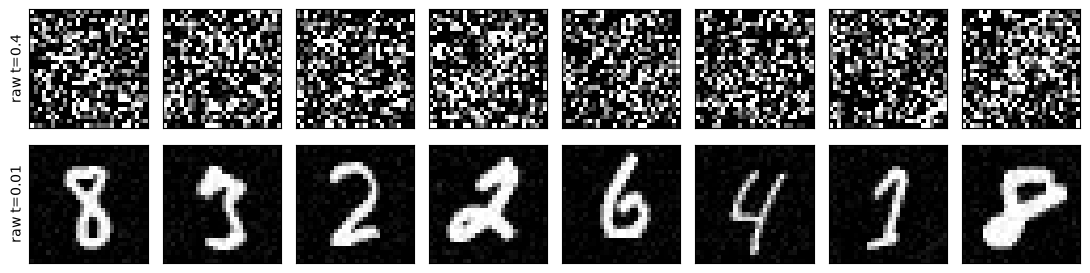

In [5]:
levels=[.8,.6,.4,.2,.01]
fig,ax=plt.subplots(len(levels)+1,8,figsize=(11,8))
for row,t in enumerate(levels):
    m,w=posterior(normal_paths[t][:8],t,data)
    for j in range(8):
        ax[row,j].imshow(m[j].reshape(28,28),cmap='gray',vmin=0,vmax=1)
        ax[row,j].set_xticks([]); ax[row,j].set_yticks([])
    ax[row,0].set_ylabel(f'mean t={t}',fontsize=9)
ix,_=nearest(m,data)
for j in range(8):
    ax[-1,j].imshow(data[ix[j]].reshape(28,28),cmap='gray',vmin=0,vmax=1)
    ax[-1,j].set_xticks([]); ax[-1,j].set_yticks([])
ax[-1,0].set_ylabel('nearest bank',fontsize=9)
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(2,8,figsize=(11,3))
for row,t in enumerate([.4,.01]):
    for j in range(8):
        ax[row,j].imshow(normal_paths[t][j].reshape(28,28),cmap='gray',vmin=0,vmax=1)
        ax[row,j].set_xticks([]); ax[row,j].set_yticks([])
    ax[row,0].set_ylabel(f'raw t={t}')
plt.tight_layout(); plt.show()

## 6. Numerical refinement and truncation checks

Compare 600 and 1,200 Euler steps for the first eight Gaussian-initialized trajectories. At fixed query positions test top-32 denoising against the full bank. The retained posterior mass reports what truncation removes. These exact logits still scan all images; this is not a claimed computational acceleration. Batch matrix multiplication avoids an explicit batch-by-bank-by-pixel tensor.

In [6]:
fine=integrate(z[:8],data,1200,stops)
for t in [.4,.1,.01]:
    raw=np.sqrt(np.mean((normal_paths[t][:8]-fine[t])**2))
    m,w=posterior(normal_paths[t][:8],t,data)
    mf,_=posterior(fine[t],t,data)
    print('time, paired raw RMSE, paired mean RMSE:',t,raw,np.sqrt(np.mean((m-mf)**2)))
for t in [.8,.4,.1]:
    x=normal_paths[t]; m,w=posterior(x,t,data)
    mk,_=posterior(x,t,data,topk=32)
    retained=np.sort(w,axis=1)[:,-32:].sum(1)
    print('time, retained mass, top-32 mean RMSE:',t,retained.mean(),np.sqrt(np.mean((m-mk)**2)))
assert all(np.isfinite(x).all() for x in normal_paths.values())

time, paired raw RMSE, paired mean RMSE: 0.4 0.001060256970694746 0.0009592450418914292
time, paired raw RMSE, paired mean RMSE: 0.1 0.0008083090811016998 9.663077650950204e-41
time, paired raw RMSE, paired mean RMSE: 0.01 0.00011993901732164364 0.0
time, retained mass, top-32 mean RMSE: 0.8 0.06032076114862689 0.11264824024228412
time, retained mass, top-32 mean RMSE: 0.4 0.928350109639376 0.009891991398877597
time, retained mass, top-32 mean RMSE: 0.1 1.0 1.3427362802718403e-48


## 7. Interpretation and limits

This is a functioning non-neural empirical-score sampler. Its posterior means are exact convex combinations of stored images up to floating-point arithmetic. Read their distances and effective counts together: a mathematically positive softmax weight can be negligible numerically, and an output can be effectively a stored image.

The test does not prove that an empirical-score ODE is a useful generalizing image generator. Positive-time posterior means intentionally define a different output law; raw positive-time states retain noise. The exact matched-law zero-noise limit is the empirical measure. An approximate Gaussian initialization, finite Euler steps, or top-k truncation does not automatically turn that law into a meaningful interpolation distribution.

No network is necessary for this construction. Larger banks, search indexes, learned representations, smoothing and model restrictions are separate design choices. The present bank is 1,000 images, not the full dataset, and no held-out quality metric is evaluated. Try additional seeds and bank sizes before drawing broader conclusions. Do not infer novelty from different pixel values alone.

**Saved-run observations.** Mean effective count fell from 912.26 at $t=0.8$ to 7.88 at $t=0.4$ and approximately 1 at $t=0.01$. All 32 denoised outputs at the lowest cutoff were within $10^{-4}$ pixel RMSE of a bank image under both initializations. The raw Gaussian-initialized states still had mean nearest-image RMSE 0.04448, consistent with residual noise rather than new clean image structure. At $t=0.4$, denoised nearest-image RMSE was 0.0978 and the figure shows mixtures of stored shapes. Doubling steps changed raw states at $t=0.01$ by 0.000120 RMS on the first eight trajectories, with no change in their final denoised outputs at displayed precision. These observations support interpolation at intermediate noise and near-retrieval at low noise in this experiment.